In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
df = pd.read_csv(r"C:/Users/Hp/Desktop/LP3/ML/sales_data_sample.csv", encoding="latin1")

print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
df = df.select_dtypes(include=[np.number])

df.drop(columns=['ORDERNUMBER'], errors='ignore', inplace=True)
df.dropna(inplace=True)

scaler = StandardScaler()
X = scaler.fit_transform(df)

print("Preprocessed data:", X.shape)

Preprocessed data: (2823, 8)


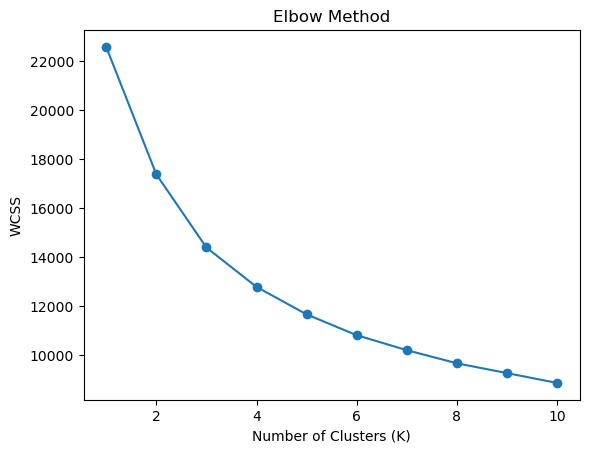

In [4]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [5]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['KMeans_Cluster'] = kmeans.fit_predict(X)

print(df['KMeans_Cluster'].value_counts())
print(df.head())

KMeans_Cluster
1    937
3    676
0    606
2    604
Name: count, dtype: int64
   QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  QTR_ID  MONTH_ID  \
0               30      95.70                2  2871.00       1         2   
1               34      81.35                5  2765.90       2         5   
2               41      94.74                2  3884.34       3         7   
3               45      83.26                6  3746.70       3         8   
4               49     100.00               14  5205.27       4        10   

   YEAR_ID  MSRP  KMeans_Cluster  
0     2003    95               0  
1     2003    95               0  
2     2003    95               1  
3     2003    95               1  
4     2003    95               1  


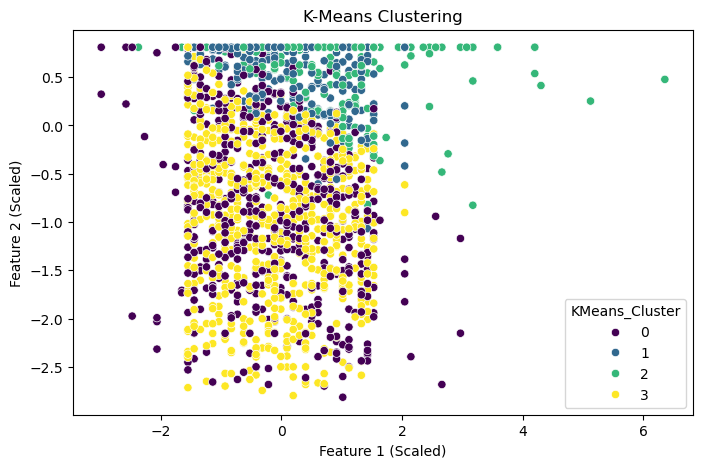

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=df['KMeans_Cluster'],
    palette='viridis'
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.show()

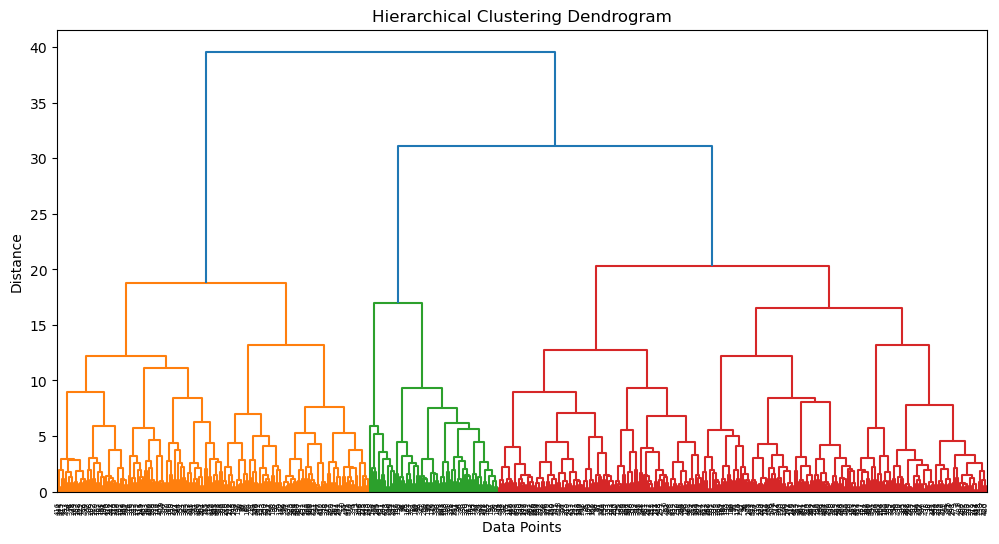

In [7]:
Z = linkage(X[:500], method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [8]:
hier_clusters = fcluster(Z, t=4, criterion='maxclust')

print("Hierarchical Cluster Labels:")
print(hier_clusters)

Hierarchical Cluster Labels:
[1 1 4 4 4 4 3 4 3 1 1 1 3 3 4 4 3 4 4 4 4 3 1 1 1 2 1 1 2 2 2 3 2 4 2 2 1
 1 2 2 4 2 4 2 2 2 3 3 4 1 1 1 1 2 1 1 3 4 4 3 4 4 3 1 1 3 1 1 3 4 4 4 4 3
 4 3 1 1 1 1 1 2 2 2 4 3 2 2 2 1 1 2 1 1 2 4 4 3 2 2 4 1 1 1 2 2 1 1 1 4 4
 4 3 3 4 1 1 3 3 3 3 3 3 4 4 3 3 4 1 1 1 2 1 1 1 1 3 3 3 4 3 3 4 1 1 1 3 3
 4 3 4 4 4 3 3 4 1 1 1 1 1 1 2 2 2 2 3 4 3 4 1 1 1 4 2 2 4 3 4 2 4 4 1 1 1
 1 2 2 2 2 4 2 2 4 2 2 1 1 1 2 2 2 4 2 4 4 4 4 1 1 1 1 1 1 3 4 3 4 4 4 4 3
 1 1 1 1 3 3 4 4 3 4 3 3 4 2 1 1 1 2 1 2 3 2 4 4 4 3 3 1 1 1 1 1 4 4 4 3 4
 3 4 1 1 1 2 1 1 1 2 4 4 3 2 4 3 1 1 1 1 3 3 4 4 4 3 4 4 4 1 1 2 1 1 4 3 4
 4 3 4 3 1 1 3 3 3 4 4 3 3 4 4 4 1 1 1 1 1 2 2 2 2 3 2 2 2 1 1 1 1 2 3 2 4
 2 3 4 4 4 1 1 1 1 1 3 3 3 3 3 3 3 4 1 1 1 1 4 4 4 3 4 4 4 4 1 1 1 1 1 1 3
 3 3 4 3 4 4 4 1 1 1 1 3 4 3 4 4 3 4 4 4 1 1 2 1 1 3 3 3 4 4 4 3 4 1 1 1 1
 4 3 3 3 3 4 4 4 1 1 1 2 1 1 1 1 4 4 4 4 3 3 4 1 1 1 1 4 3 4 4 4 3 3 4 4 1
 1 1 1 2 1 1 3 3 3 3 4 3 4 1 1 1 3 3 3 4 4 4 4 4 4 4 1 1 1 2 1 1 1 1 3 

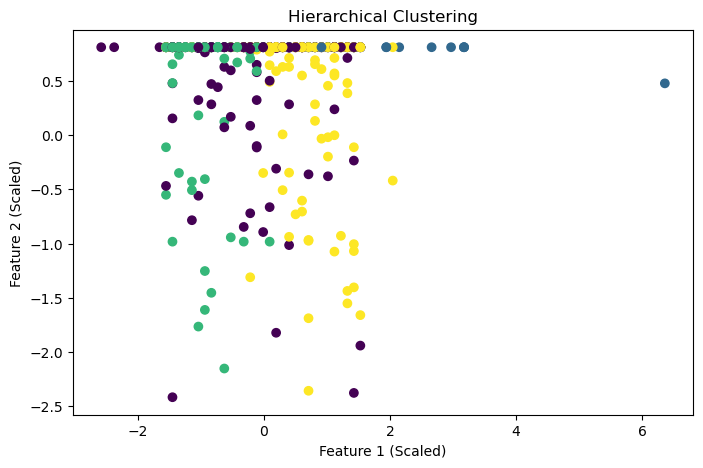

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:500, 0],
    X[:500, 1],
    c=hier_clusters,
    cmap='viridis'
)

plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.show()